# Processed Dataset Overview

This notebook checks the class balance of the processed sentiment dataset before model training.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROCESSED_DATA_PATH = Path(
    "../data/processed/video_games_reviews_cleaned.csv"
)

processed_reviews = pd.read_csv(
    PROCESSED_DATA_PATH,
    usecols=["overall", "sentiment"]
)

print(f"Processed rows: {len(processed_reviews):,}")
processed_reviews.head()

Processed rows: 473,972


,overall,sentiment
0,5.0,positive
1,4.0,positive
2,3.0,neutral
3,2.0,negative
4,5.0,positive


In [2]:
sentiment_order = ["negative", "neutral", "positive"]

class_counts = (
    processed_reviews["sentiment"]
    .value_counts()
    .reindex(sentiment_order)
)

class_percentages = (
    class_counts / class_counts.sum() * 100
).round(2)

class_summary = pd.DataFrame({
    "review_count": class_counts,
    "percentage": class_percentages
})

class_summary

,review_count,percentage
sentiment,,
negative,51974,10.97
neutral,46554,9.82
positive,375444,79.21


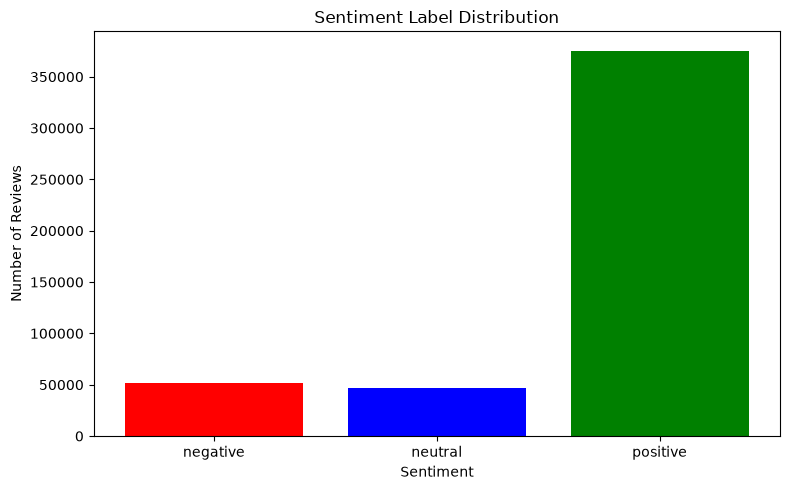

In [5]:
plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.index,
    class_counts.values,
    color=["red", "blue", "green"]
)

plt.title("Sentiment Label Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

## Class Balance Conclusion

The processed dataset is strongly imbalanced, with positive reviews representing roughly four-fifths of the available records.

Accuracy alone would therefore be misleading because a model could achieve a high score by favouring the positive class. For this reason, the later train-test split will preserve class proportions, macro F1-score will be used as a key comparison metric, and class weighting will be considered for suitable models.